## **Phase 2 (Peer Review)**

#### Project Information

**Research question(s)**

Looking at F1 qualifying from 2023–2025, we want to know whether circuit conditions (mainly elevation and temperature) affect teams differently once we look at relative pace instead of raw lap time.

More specifically:
1. Does elevation help some teams and hurt others relative to their usual pace?
2. Does Mercedes look stronger than usual in cooler weather (and maybe under more cloud cover during day sessions) compared to other teams?

**Data description** (analysis-ready data: `analysis_ready.csv`)

Inspired by Gebru et al. (2018), Datasheets for Datasets:

- **Observations (rows):** One row = one team in one qualifying session (2023–2025). **n = 870**.
- **Attributes (columns):** `year`, `circuit_short_name`, `team_name`, `date_start_est`, `best_lap_s`, `pole_s`, `gap_to_pole_pct`, `season_avg_gap_pct`, `relative_pace`, `temperature_2m`, `cloud_cover`, `elevation_m`, `is_night`, `is_mexico_city`, `is_mercedes`.
- **Why created:** To study whether weather and elevation change *team-relative* qualifying pace, not just who is fastest overall.
- **How created:** OpenF1 sessions/drivers/laps + Open-Meteo hourly weather at session start. Team best lap → % gap to pole → subtract that team’s season-average gap (= `relative_pace`). Circuit elevations joined by circuit name.
- **What influenced what was recorded:** OpenF1 covers 2023 onward; one qualifying session lacked lap data and was dropped. Weather is the hour of session start (EST), not minute-by-minute trackside sensors. Open-Meteo is reanalysis on an ~11–25 km grid.
- **Preprocessing:** Keep Race/Qualifying, drop cancelled and 2026; exclude pit-out laps; aggregate to team-session; merge weather + elevation. Relative pace centered within team-year.
- **People:** Timing/weather are public motorsport/meteorology products; drivers are public figures in race broadcasts. No private survey data.
- **Raw sources:** [OpenF1](https://openf1.org/docs/), [Open-Meteo Historical API](https://open-meteo.com/en/docs/historical-weather-api). Analysis-ready file in this repo: `analysis_ready.csv`.


OpenF1 gave us session times, teams, and qualifying laps. Open-Meteo filled in temperature, cloud cover, and related weather at each circuit’s coordinates for the session-start hour.


*(See combined data description above for both F1 and weather sources.)*


Circuit lat/long were looked up by `circuit_short_name`, then used to pull matching Open-Meteo hours.


**Data limitations**

- **Hourly weather:** Sessions last 1–2 hours; we only observe the start hour. Mid-session weather shifts (rain, cloud clearing) are missed and can misclassify conditions, weakening temperature/cloud associations.
- **Elevation is uneven:** A lot of tracks are pretty low; a couple are much higher. If we treat elevation as one continuous variable, those high tracks might pull the slope around, so we should also try the model without them.
- **Cars change within a season:** Season-average gap assumes a stable team baseline. Upgrades and driver swaps mean `relative_pace` mixes true condition effects with car development.
- **Air vs track temperature:** We use Open-Meteo `temperature_2m`, not rubbered-in track temp. Tire-grip claims (e.g. Mercedes in the cool) may be only partly captured.
- **Night races & cloud cover:** Clouds matter less at night for track heating; including night sessions can dilute cloud-cover effects unless we filter or add a day/night term.
- **Precipitation rarity:** Rain is zero for most sessions, so wet-weather effects would rest on a very small sample.
- **Coverage gaps:** OpenF1 starts in 2023; one qualifying session had no laps. Results generalize only to recent regulation eras.


### Part 2: Preregistration of Analyses

**How we measure performance:** For each team at each qualifying session, we take the team’s fastest lap at Q1 (faster of its two drivers) and measure how far behind it was compared to the fastest lap of Q1 in the session, as a percentage. We use Q1 because it’s the only segment in which every car runs on the track conditions closest to being equal, meaning the comparison isn’t biased or distorted by teams being eliminated before the track gets faster. We then subtract the team’s average gap for the season to get its relative pace. A negative value means the team was quicker than usual that weekend; a positive value means it was slower. This tells us whether conditions changed a team’s performance, not just who’s faster.

#### Preregistration Statement 1

**Hypothesis:** Elevation affects teams differently: some teams are relatively quicker on high-altitude circuits, while others are slower because of how their cars are built.

**Reasoning:** Air is thinner at high altitudes, which reduces downforce and makes cooling more difficult. Many teams design their cars around different trade-offs, so altitude should affect everyone differently.

**Analysis:** We will run a linear regression with relative pace as the outcome and circuit elevation, team dummy variables, and elevation × team interaction terms as predictors, using Ferrari as the reference team. We will test whether any interaction coefficient differs from 0. We’ll also rerun it without the highest-altitude track(s), just to make sure one circuit isn’t driving the whole elevation result.

#### Pre-registration Statement 2

**Hypothesis:** Mercedes performs better than usual when it’s cooler.

**Reasoning:** Tires only grip well within a certain temperature range. During 2024–2025 Mercedes said their cars work best in cooler conditions.

**Analysis:** We will run a linear regression with relative pace as the outcome and air temperature (`temperature_2m`), a Mercedes dummy (1 if Mercedes, 0 otherwise), and the interaction temperature × Mercedes. We’ll test whether that interaction is > 0 (Mercedes getting relatively worse as it gets hotter). We’ll also try the same setup with cloud cover instead of temperature, but only for daytime sessions, since cloud cover is less relevant at night.

#### Questions for Reviewers
- Most tracks aren’t that high, but a few are. Is continuous elevation fine, or should we also just compare high vs low altitude tracks?
- Teams change their cars during the season; how should we treat the full-season average? Or should we focus on individual races?
- Should we drop night races from the cloud cover analysis or keep them and add a night/day variable? In other words, should we have an added day/night robustness check?
- Is it better to check by Q1 or better to check by a team’s fastest lap and measure how far behind pole position it was? By checking with Q1, we obtain conditions close to equal for all drivers, but in exchange there are teams that may use used tires or one run to get through, making their Q1 gap distorted compared to their true pace, which would affect Mercedes in Statement 2. Otherwise, checking by pole position would also introduce distortion by comparing teams eliminated in Q1 against a faster Q3 track overall, biasing our outcomes in both analyses.


#### Data cleaning

##### Libraries

In [49]:
# installing necessary libraries
%pip install seaborn pandas duckdb requests numpy

Note: you may need to restart the kernel to use updated packages.


In [50]:
# loading necessary libraries and packages to handle our data
import requests # to extract from datasets
import pandas as pd # to handle the dataframes
import duckdb # to clean the data
from datetime import datetime # to handle the date time format

Note for above code chunk(s), will be modifying and editing as we go to ensure we have what we need to handle our data.

##### Race Session Import and Cleansing

In [51]:
# code OpenF1 API informs us to use to import
from urllib.request import urlopen
import json
response = urlopen('https://api.openf1.org/v1/sessions')
data = json.loads(response.read().decode('utf-8'))
temp_races_df = pd.DataFrame(data) # last line of provided code from API

For above code, this was provided by OpenF1 API in (https://openf1.org/docs) for information on how to import/scrape.

In [52]:
temp_races_df # checking the column headers
temp_races_df['session_type'].unique() # checking to see what the different types are to make sure we don't truncate

# selecting the wanted columns and races
races_df = duckdb.sql("SELECT session_key, session_type, session_name, date_start, date_end, circuit_short_name, country_name, location, year \
                      FROM temp_races_df WHERE ((session_type = 'Race' OR session_type = 'Qualifying') AND is_cancelled = False) \
                      AND year < 2026").df()
races_df # checking the product and modifying sql as necessary to prune canceled races and races from 2026 (ongoing) season
races_df['date_start'] = pd.to_datetime(races_df['date_start'], format='mixed') # reformat dates
races_df['date_end'] = pd.to_datetime(races_df['date_end'], format='mixed')
# wanting to uniform the time zone and make it more easily comprehensible for human reading
races_df['date_start'] = races_df['date_start'].dt.tz_convert("EST").dt.tz_localize(None)
races_df['date_end'] = races_df['date_end'].dt.tz_convert("EST").dt.tz_localize(None)
races_df # checking date time

,session_key,session_type,session_name,date_start,date_end,circuit_short_name,country_name,location,year
0,7768,Qualifying,Qualifying,2023-03-04 10:00:00,2023-03-04 11:00:00,Sakhir,Bahrain,Sakhir,2023
1,7953,Race,Race,2023-03-05 10:00:00,2023-03-05 12:00:00,Sakhir,Bahrain,Sakhir,2023
2,7775,Qualifying,Qualifying,2023-03-18 12:00:00,2023-03-18 13:00:00,Jeddah,Saudi Arabia,Jeddah,2023
3,7779,Race,Race,2023-03-19 12:00:00,2023-03-19 14:00:00,Jeddah,Saudi Arabia,Jeddah,2023
4,7783,Qualifying,Qualifying,2023-04-01 01:00:00,2023-04-01 02:00:00,Melbourne,Australia,Melbourne,2023
...,...,...,...,...,...,...,...,...,...
171,9845,Race,Sprint,2025-11-29 09:00:00,2025-11-29 10:00:00,Lusail,Qatar,Lusail,2025
172,9846,Qualifying,Qualifying,2025-11-29 13:00:00,2025-11-29 14:00:00,Lusail,Qatar,Lusail,2025
173,9850,Race,Race,2025-11-30 11:00:00,2025-11-30 13:00:00,Lusail,Qatar,Lusail,2025
174,9835,Qualifying,Qualifying,2025-12-06 09:00:00,2025-12-06 10:00:00,Yas Marina Circuit,United Arab Emirates,Yas Island,2025


Here, we have cleaned a DataFrame to contain the dates and times for races and the races that qualify the teams to participate in the larger race for narrowing down the time and date for the weather conditions. We also made sure to maintain the specific names of the locations to further assist us when looping in information from Open Meteo. We found the session types listed were `[Practice, Qualifying, Race]` and chose to disregard Practices since teams use these for practice and performance may not be up to par; in other words, since the teams are warming up or practicing on the track, the information consumed may not be as relevant to driver overall performance when representing their team name. One other important thing to note is that we filtered out the race dates from 2026. Since the 2026 F1 season is still ongoing, these races will lack information about the performance of teams and their drivers. We prefer to handle a constantly changing dataset, so we decided to stick with 2023, 2024, and 2025 where all the data is set.

##### Open F1 weather data

In [21]:
import time

quali_keys = duckdb.sql("SELECT session_key FROM races_df WHERE session_type = 'Qualifying'").df()['session_key']

weather_list = []
for key in quali_keys:
    response = urlopen(f'https://api.openf1.org/v1/weather?session_key={key}')
    weather_list.append(pd.DataFrame(json.loads(response.read().decode('utf-8'))))
    print(key)
    time.sleep(2.1)
temp_f1_weather_df = pd.concat(weather_list, ignore_index=True)

# we should convert to naive EST so it matches races_df
temp_f1_weather_df['date'] = pd.to_datetime(temp_f1_weather_df['date'], format='mixed').dt.tz_convert("EST").dt.tz_localize(None)

7768
7775
7783
9064
9278
9074
9090
9098
9106
9112
9282
9122
9129
9135
9286
9145
9153
9161
9169
9215
9298
9207
9294
9177
9304
9308
9314
9193
9468
9476
9484
9492
9668
9664
9502
9498
9511
9519
9527
9535
9545
9541
9554
9562
9570
9578
9586
9594
9602
9612
9608
9621
9631
9627
9640
9650
9646
9658
9689
9989
9994
10002
10010
10018
10024
10029
9983
9975
9967
9959
9951
9943
9930
9935
9924
9916
9908
9900
9892
9879
9884
9873
9860
9865
9854
9841
9846
9835


Here, we pull weather information from OpenF1’s weather endpoint (https://openf1.org/docs/#weather). Unlike Open Meteo, OpenF1 records weather directly at the track about once every minute, including track temperature, which Open Meteo does not have. Since we needed track temperature for our second preregistration statement, we looped through every qualifying session key and pulled its weather readings one at a time, making sure to add in pauses amounting to 2.1 seconds between each request to stay within OpenF1’s rate limit. I thought it'd be helpful to then convert the dates to EST so they would match the data in races_df, which is also in ET. I also found it helpful to add print(key) to track the progress; I was unsure of the code's progress without it. I had to slow down the pull requests by increase the value in time.sleep() as time.sleep(0.5) proved too much for the server to handle.

In [25]:
f1_weather_df = duckdb.sql("SELECT weather.session_key, AVG(weather.track_temperature) AS track_temp, AVG(weather.air_temperature) AS air_temp_f1, \
                           AVG(weather.humidity) AS humidity, MAX(weather.rainfall) > 0 AS rain_any, COUNT(*) AS n_readings \
                           FROM temp_f1_weather_df weather JOIN races_df races ON weather.session_key = races.session_key \
                           WHERE weather.date BETWEEN races.date_start AND races.date_end GROUP BY weather.session_key").df()
f1_weather_df #weathers
print(f1_weather_df)

    session_key  track_temp  air_temp_f1   humidity  rain_any  n_readings
0          7783   22.210000    15.175000  53.400000     False          20
1          9215   34.370000    31.401667  56.116667     False          60
2          9608   38.143333    28.595000  38.316667     False          60
3          9916   34.228333    20.616667  64.416667     False          60
4          9193   31.753333    26.716667  66.350000     False          60
..          ...         ...          ...        ...       ...         ...
83         9621   39.048333    21.931667  40.350000     False          60
84         9689   40.630000    29.880000  46.933333     False          60
85        10029   41.642373    28.089831  62.491525     False          59
86         9967   46.890000    29.143333  37.333333     False          60
87         9943   27.465000    20.133333  73.550000     False          60

[88 rows x 6 columns]


We narrow the weather readings down to only those taken during each qualifying session by keeping readings between the session’s start and end times. We then averaged the track temperature, air temperature, and humidity so that each session has one set of weather values. We also marked a session as rainy if any reading during it showed rainfall, since we plan to specially allocate wet sessions from our analyses. Lastly, we counted how many readings went into each average; since readings come about once a minute, a one-hour session should have around 60, which helps us check that the times lined up correctly between one race and another.

##### Drivers and Their Teams Import and Cleansing

In [53]:
# code OpenF1 API informs us to use to import
response = urlopen('https://api.openf1.org/v1/drivers')
data = json.loads(response.read().decode('utf-8'))
temp_drivers_df = pd.DataFrame(data) # last line of provided code from API

For above code, this was provided by OpenF1 API in (https://openf1.org/docs) for information on how to import/scrape.

In [54]:
temp_drivers_df # checking the column headers
temp_drivers_df['broadcast_name'].unique() # seeing who is really driver because original is 10k lines

drivers_df = duckdb.sql("SELECT DISTINCT r.year, d.driver_number, d.full_name, d.name_acronym, d.team_name, d.country_code \
                      FROM temp_drivers_df d JOIN races_df r ON r.session_key = d.session_key ORDER BY d.full_name, d.team_name, r.year").df()
drivers_df

,year,driver_number,full_name,name_acronym,team_name,country_code
0,2023,23,Alexander ALBON,ALB,Williams,THA
1,2024,23,Alexander ALBON,ALB,Williams,THA
2,2025,23,Alexander ALBON,ALB,Williams,NaN
3,2023,55,Carlos SAINZ,SAI,Ferrari,ESP
4,2024,55,Carlos SAINZ,SAI,Ferrari,ESP
...,...,...,...,...,...,...
65,2024,22,Yuki TSUNODA,TSU,RB,JPN
66,2025,22,Yuki TSUNODA,TSU,Racing Bulls,NaN
67,2025,22,Yuki TSUNODA,TSU,Red Bull Racing,NaN
68,2023,24,ZHOU Guanyu,ZHO,Alfa Romeo,CHN


Here, we have cleaned a DataFrame to contain the names, team names, years, and countries of the drivers. One thing that makes this dataset difficult to handle is how the same driver might have different driver numbers or teams or country associations year to year. This is something we will have to deal with as we analyze the data. I decided to join the race date information to help add understanding to the team associations. Since team associations might shift year to year, this helps narrow it down. Additionally, joining on the session keys helps ensure we aren't including information from practices since the session keys from `races_df` would be pruned down by date, race cancellation, etc. We choose to focus on `session_key` and not `meeting_key` since `meeting_key` is specific to special meets and chunks entire weekends together. `session_key` keeps each individual track session separate, which is far more specific.

##### Weather Information Import and Cleansing

In [55]:
races_df['circuit_short_name'].unique() # to print out the entire full list of circuit names scrollable

# research each circuit name for latitude and longitude
circuit_coords = {
    # OpenF1 circuit_short_name: (latitude, longitude) # full name
    "Sakhir": (26.0325, 50.5106),   # Bahrain International Circuit
    "Jeddah": (21.6319, 39.1044),   # Jeddah Corniche Circuit
    "Melbourne": (-37.8497, 144.9680),   # Albert Park
    "Baku": (40.3725, 49.8533),   # Baku City Circuit
    "Miami": (25.9581, -80.2389),   # Miami International Autodrome
    "Monte Carlo": (43.7347, 7.4206),   # Circuit de Monaco
    "Catalunya": (41.5700, 2.2611),   # Circuit de Barcelona-Catalunya
    "Montreal": (45.5017, -73.5228),   # Circuit Gilles Villeneuve
    "Spielberg": (47.2197, 14.7647),   # Red Bull Ring
    "Silverstone": (52.0786, -1.0169),   # Silverstone Circuit
    "Hungaroring": (47.5789, 19.2486),   # Hungaroring
    "Spa-Francorchamps": (50.4372, 5.9714),   # Circuit de Spa-Francorchamps
    "Zandvoort": (52.3888, 4.5409),   # Circuit Zandvoort
    "Monza": (45.6156, 9.2811),   # Autodromo Nazionale Monza
    "Singapore": (1.2914, 103.8640),   # Marina Bay Street Circuit
    "Suzuka": (34.8431, 136.5410),   # Suzuka International Racing Course
    "Lusail": (25.4900, 51.4542),   # Lusail International Circuit
    "Austin": (30.1328, -97.6411),   # Circuit of the Americas
    "Mexico City": (19.4042, -99.0907),   # Autódromo Hermanos Rodríguez
    "Interlagos": (-23.7036, -46.6997),   # Autódromo José Carlos Pace
    "Las Vegas": (36.1147, -115.1728),   # Las Vegas Strip Circuit
    "Yas Marina Circuit": (24.4672, 54.6031),   # Yas Marina Circuit
    "Shanghai": (31.3389, 121.2197),   # Shanghai International Circuit
    "Imola": (44.3439, 11.7167),   # Autodromo Enzo e Dino Ferrari
}

coords_df = pd.DataFrame.from_dict(circuit_coords, orient='index', columns=['latitude', 'longitude']).rename_axis("circuit_short_name").reset_index()
coords_df # ensure it looks correct

# prepping to input information to Open Meteo in their specified format
# latitude, longitude, , timezone, start date, end date
temp_races_df['date_start'] = races_df['date_start'].dt.strftime("%Y-%m-%d")
temp_races_df['date_end'] = races_df['date_end'].dt.strftime("%Y-%m-%d")
openmeteo_input_df = duckdb.sql("SELECT c.latitude, c.longitude, r.date_start, r.date_end FROM coords_df c JOIN temp_races_df r \
                                ON c.circuit_short_name = r.circuit_short_name WHERE r.date_start != 'NaN' AND r.date_end != 'NaN'").df()
timezone_filler = [',EST'] * 176
openmeteo_input_df.insert(loc=2, column='timezone', value=timezone_filler)
openmeteo_input_df # print to see if format good

openmeteo_input_df['hour'] = races_df['date_start'].dt.strftime("%H")

Above, we modified our existing datasets and information to be able to input it to Open Meteo more easily.

In [56]:
# code provided to us to input for importing data by the Open Meteo website
%pip install openmeteo-requests
%pip install requests-cache retry-requests numpy pandas

import openmeteo_requests
import requests_cache
from retry_requests import retry

# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [57]:
# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
def openmeteo_pull(lat, long, start, end, spec_hour):
	url = "https://archive-api.open-meteo.com/v1/archive"
	params = {
		"latitude": [lat],
		"longitude": [long],
		"start_date": [start],
		"end_date": [end],
		"hourly": ["temperature_2m", "precipitation", "cloud_cover_low", "cloud_cover_high", "cloud_cover_mid", "cloud_cover", "surface_pressure", "wind_speed_10m", "wind_direction_10m", "wind_gusts_10m", "wind_direction_100m", "wind_speed_100m"],
		"timezone": ["EST"],
	}
	responses = openmeteo.weather_api(url, params = params)

	# Process 8 locations
	for response in responses:
		#print(f"\nCoordinates: {response.Latitude()}°N {response.Longitude()}°E")
		#print(f"Elevation: {response.Elevation()} m asl")
		#print(f"Timezone: {response.Timezone()}{response.TimezoneAbbreviation()}")
		#print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")
		
		# Process hourly data. The order of variables needs to be the same as requested.
		hourly = response.Hourly()
		hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
		hourly_precipitation = hourly.Variables(1).ValuesAsNumpy()
		hourly_cloud_cover_low = hourly.Variables(2).ValuesAsNumpy()
		hourly_cloud_cover_high = hourly.Variables(3).ValuesAsNumpy()
		hourly_cloud_cover_mid = hourly.Variables(4).ValuesAsNumpy()
		hourly_cloud_cover = hourly.Variables(5).ValuesAsNumpy()
		hourly_surface_pressure = hourly.Variables(6).ValuesAsNumpy()
		hourly_wind_speed_10m = hourly.Variables(7).ValuesAsNumpy()
		hourly_wind_direction_10m = hourly.Variables(8).ValuesAsNumpy()
		hourly_wind_gusts_10m = hourly.Variables(9).ValuesAsNumpy()
		hourly_wind_direction_100m = hourly.Variables(10).ValuesAsNumpy()
		hourly_wind_speed_100m = hourly.Variables(11).ValuesAsNumpy()
		
		hourly_data = {
			"date": pd.date_range(
				start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
				end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
				freq = pd.Timedelta(seconds = hourly.Interval()),
				inclusive = "left"
			).tz_convert(response.Timezone().decode())
		}

		mask = (hourly_data['date'].hour == spec_hour)

		hourly_data["date"] = hourly_data["date"][mask]
		
		hourly_data["temperature_2m"] = hourly_temperature_2m[mask]
		hourly_data["precipitation"] = hourly_precipitation[mask]
		hourly_data["cloud_cover_low"] = hourly_cloud_cover_low[mask]
		hourly_data["cloud_cover_high"] = hourly_cloud_cover_high[mask]
		hourly_data["cloud_cover_mid"] = hourly_cloud_cover_mid[mask]
		hourly_data["cloud_cover"] = hourly_cloud_cover[mask]
		hourly_data["surface_pressure"] = hourly_surface_pressure[mask]
		hourly_data["wind_speed_10m"] = hourly_wind_speed_10m[mask]
		hourly_data["wind_direction_10m"] = hourly_wind_direction_10m[mask]
		hourly_data["wind_gusts_10m"] = hourly_wind_gusts_10m[mask]
		hourly_data["wind_direction_100m"] = hourly_wind_direction_100m[mask]
		hourly_data["wind_speed_100m"] = hourly_wind_speed_100m[mask]
		
		hourly_dataframe = pd.DataFrame(data = hourly_data)
		return hourly_dataframe
		# print("\nHour data\n", hourly_dataframe)

weather_list = []
# go through every item of the input csv and add it to a consolidated dataframe with all the information
for value in openmeteo_input_df.itertuples():
	weather_list.append(openmeteo_pull(value.latitude, value.longitude, value.date_start, value.date_end, int(value.hour)))
weather_df = pd.concat(weather_list, ignore_index=True)

weather_df['date'] = weather_df['date'].dt.tz_localize(None) # reformat date to match our other date columns
weather_df

,date,temperature_2m,precipitation,cloud_cover_low,cloud_cover_high,cloud_cover_mid,cloud_cover,surface_pressure,wind_speed_10m,wind_direction_10m,wind_gusts_10m,wind_direction_100m,wind_speed_100m
0,2023-03-04 10:00:00,23.250,0.0,0.0,0.0,0.0,0.0,1017.361511,12.605142,88.363464,24.119999,89.045181,21.602999
1,2023-03-05 10:00:00,27.850,0.0,0.0,0.0,0.0,0.0,1016.676453,9.779817,173.659897,16.199999,173.659897,13.039754
2,2023-03-18 12:00:00,20.850,0.0,0.0,8.0,0.0,8.0,1010.660095,10.464798,356.054901,16.199999,350.706757,20.063339
3,2023-03-19 12:00:00,25.000,0.0,0.0,0.0,0.0,0.0,1006.776733,17.106628,98.471062,24.840000,108.667007,28.119204
4,2023-04-01 01:00:00,22.150,0.0,9.0,0.0,0.0,9.0,1014.160950,40.323212,339.623474,60.120003,340.232727,48.965294
...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,2025-11-29 09:00:00,6.157,0.0,3.0,21.0,0.0,23.0,934.307373,0.900000,126.869987,9.360000,135.000107,4.327494
176,2025-11-29 13:00:00,1.407,0.0,1.0,90.0,16.0,91.0,934.178406,0.648999,236.309906,4.680000,272.862335,3.604497
177,2025-11-30 11:00:00,3.207,0.0,0.0,100.0,0.0,100.0,932.754089,0.254558,135.000107,3.600000,360.000000,2.340000
178,2025-12-06 09:00:00,5.407,0.0,1.0,100.0,23.0,100.0,933.916992,2.226477,284.036255,16.199999,262.304047,6.720535


Open Meteo API provided us with specific Python we could use to extract our data. Since Open Meteo had a URI length limit, we could not input all 176 lines of coordinates and days. For this reason, we made it into a function that could be called upon multiple times. We did use our understanding of Python to modify the given code to isolate a singular hour or section of time in order to prevent being overloaded with the entire day's information. This simply involved adding the `mask` variable. Now that the start dates match up, the information can now be compared with our race and driver data much more cleanly. We commented out the print statements to prevent the screen from flooding. To see the code Open Meteo provided, click [here](https://open-meteo.com/en/docs/historical-weather-api?location_mode=csv_coordinates&csv_coordinates=26.0325,50.5106,,EST,2023-03-04,2023-03-04%0A26.0325,50.5106,,EST,2023-03-05,2023-03-05%0A26.0325,50.5106,,EST,2023-03-18,2023-03-18%0A26.0325,50.5106,,EST,2023-03-19,2023-03-19%0A26.0325,50.5106,,EST,2023-04-01,2023-04-01%0A26.0325,50.5106,,EST,2023-04-02,2023-04-02%0A26.0325,50.5106,,EST,2023-04-28,2023-04-28%0A26.0325,50.5106,,EST,2023-04-29,2023-04-29%0A21.6319,39.1044,,EST,2023-04-29,2023-04-29%0A21.6319,39.1044,,EST,2023-04-30,2023-04-30%0A21.6319,39.1044,,EST,2023-05-06,2023-05-06%0A21.6319,39.1044,,EST,2023-05-07,2023-05-07%0A21.6319,39.1044,,EST,2023-05-27,2023-05-27%0A-37.8497,144.968,,EST,2023-05-28,2023-05-28%0A-37.8497,144.968,,EST,2023-06-03,2023-06-03%0A-37.8497,144.968,,EST,2023-06-04,2023-06-04%0A-37.8497,144.968,,EST,2023-06-17,2023-06-17%0A-37.8497,144.968,,EST,2023-06-18,2023-06-18%0A40.3725,49.8533,,EST,2023-06-30,2023-06-30%0A40.3725,49.8533,,EST,2023-07-01,2023-07-01%0A40.3725,49.8533,,EST,2023-07-01,2023-07-01%0A40.3725,49.8533,,EST,2023-07-02,2023-07-02%0A40.3725,49.8533,,EST,2023-07-08,2023-07-08%0A25.9581,-80.2389,,EST,2023-07-09,2023-07-09%0A25.9581,-80.2389,,EST,2023-07-22,2023-07-22%0A25.9581,-80.2389,,EST,2023-07-23,2023-07-23%0A25.9581,-80.2389,,EST,2023-07-28,2023-07-28%0A25.9581,-80.2389,,EST,2023-07-29,2023-07-29%0A44.3439,11.7167,,EST,2023-07-29,2023-07-29%0A44.3439,11.7167,,EST,2023-07-30,2023-07-30%0A44.3439,11.7167,,EST,2023-08-26,2023-08-26%0A44.3439,11.7167,,EST,2023-08-27,2023-08-27%0A44.3439,11.7167,,EST,2023-09-02,2023-09-02%0A43.7347,7.4206,,EST,2023-09-03,2023-09-03%0A43.7347,7.4206,,EST,2023-09-16,2023-09-16%0A43.7347,7.4206,,EST,2023-09-17,2023-09-17%0A43.7347,7.4206,,EST,2023-09-23,2023-09-23%0A43.7347,7.4206,,EST,2023-09-24,2023-09-24%0A41.57,2.2611,,EST,2023-10-06,2023-10-06%0A41.57,2.2611,,EST,2023-10-07,2023-10-07%0A41.57,2.2611,,EST,2023-10-07,2023-10-07%0A41.57,2.2611,,EST,2023-10-08,2023-10-08%0A41.57,2.2611,,EST,2023-10-20,2023-10-20%0A45.5017,-73.5228,,EST,2023-10-21,2023-10-21%0A45.5017,-73.5228,,EST,2023-10-21,2023-10-21%0A45.5017,-73.5228,,EST,2023-10-22,2023-10-22%0A45.5017,-73.5228,,EST,2023-10-28,2023-10-28%0A45.5017,-73.5228,,EST,2023-10-29,2023-10-29%0A47.2197,14.7647,,EST,2023-11-03,2023-11-03%0A47.2197,14.7647,,EST,2023-11-04,2023-11-04%0A47.2197,14.7647,,EST,2023-11-04,2023-11-04%0A47.2197,14.7647,,EST,2023-11-05,2023-11-05%0A47.2197,14.7647,,EST,2023-11-18,2023-11-18%0A52.0786,-1.0169,,EST,2023-11-19,2023-11-19%0A52.0786,-1.0169,,EST,2023-11-25,2023-11-25%0A52.0786,-1.0169,,EST,2023-11-26,2023-11-26%0A52.0786,-1.0169,,EST,2024-03-01,2024-03-01%0A52.0786,-1.0169,,EST,2024-03-02,2024-03-02%0A47.5789,19.2486,,EST,2024-03-08,2024-03-08%0A47.5789,19.2486,,EST,2024-03-09,2024-03-09%0A47.5789,19.2486,,EST,2024-03-23,2024-03-23%0A47.5789,19.2486,,EST,2024-03-23,2024-03-24%0A47.5789,19.2486,,EST,2024-04-06,2024-04-06%0A50.4372,5.9714,,EST,2024-04-07,2024-04-07%0A50.4372,5.9714,,EST,2024-04-19,2024-04-19%0A50.4372,5.9714,,EST,2024-04-19,2024-04-19%0A50.4372,5.9714,,EST,2024-04-20,2024-04-20%0A50.4372,5.9714,,EST,2024-04-21,2024-04-21%0A52.3888,4.5409,,EST,2024-05-03,2024-05-03%0A52.3888,4.5409,,EST,2024-05-04,2024-05-04%0A52.3888,4.5409,,EST,2024-05-04,2024-05-04%0A52.3888,4.5409,,EST,2024-05-05,2024-05-05%0A52.3888,4.5409,,EST,2024-05-18,2024-05-18%0A45.6156,9.2811,,EST,2024-05-19,2024-05-19%0A45.6156,9.2811,,EST,2024-05-25,2024-05-25%0A45.6156,9.2811,,EST,2024-05-26,2024-05-26%0A45.6156,9.2811,,EST,2024-06-08,2024-06-08%0A45.6156,9.2811,,EST,2024-06-09,2024-06-09%0A1.2914,103.864,,EST,2024-06-22,2024-06-22%0A1.2914,103.864,,EST,2024-06-23,2024-06-23%0A1.2914,103.864,,EST,2024-06-28,2024-06-28%0A1.2914,103.864,,EST,2024-06-29,2024-06-29%0A1.2914,103.864,,EST,2024-06-29,2024-06-29%0A34.8431,136.541,,EST,2024-06-30,2024-06-30%0A34.8431,136.541,,EST,2024-07-06,2024-07-06%0A34.8431,136.541,,EST,2024-07-07,2024-07-07%0A34.8431,136.541,,EST,2024-07-20,2024-07-20%0A34.8431,136.541,,EST,2024-07-21,2024-07-21%0A25.49,51.4542,,EST,2024-07-27,2024-07-27%0A25.49,51.4542,,EST,2024-07-28,2024-07-28%0A25.49,51.4542,,EST,2024-08-24,2024-08-24%0A25.49,51.4542,,EST,2024-08-25,2024-08-25%0A25.49,51.4542,,EST,2024-08-31,2024-08-31%0A30.1328,-97.6411,,EST,2024-09-01,2024-09-01%0A30.1328,-97.6411,,EST,2024-09-14,2024-09-14%0A30.1328,-97.6411,,EST,2024-09-15,2024-09-15%0A30.1328,-97.6411,,EST,2024-09-21,2024-09-21%0A30.1328,-97.6411,,EST,2024-09-22,2024-09-22%0A19.4042,-99.0907,,EST,2024-10-18,2024-10-18%0A19.4042,-99.0907,,EST,2024-10-19,2024-10-19%0A19.4042,-99.0907,,EST,2024-10-19,2024-10-19%0A19.4042,-99.0907,,EST,2024-10-20,2024-10-20%0A19.4042,-99.0907,,EST,2024-10-26,2024-10-26%0A-23.7036,-46.6997,,EST,2024-10-27,2024-10-27%0A-23.7036,-46.6997,,EST,2024-11-01,2024-11-01%0A-23.7036,-46.6997,,EST,2024-11-02,2024-11-02%0A-23.7036,-46.6997,,EST,2024-11-03,2024-11-03%0A-23.7036,-46.6997,,EST,2024-11-03,2024-11-03%0A36.1147,-115.1728,,EST,2024-11-23,2024-11-23%0A36.1147,-115.1728,,EST,2024-11-24,2024-11-24%0A36.1147,-115.1728,,EST,2024-11-29,2024-11-29%0A36.1147,-115.1728,,EST,2024-11-30,2024-11-30%0A36.1147,-115.1728,,EST,2024-11-30,2024-11-30%0A24.4672,54.6031,,EST,2024-12-01,2024-12-01%0A24.4672,54.6031,,EST,2024-12-07,2024-12-07%0A24.4672,54.6031,,EST,2024-12-08,2024-12-08%0A24.4672,54.6031,,EST,2025-03-15,2025-03-15%0A24.4672,54.6031,,EST,2025-03-15,2025-03-16%0A26.0325,50.5106,,EST,2025-03-21,2025-03-21%0A26.0325,50.5106,,EST,2025-03-21,2025-03-21%0A26.0325,50.5106,,EST,2025-03-22,2025-03-22%0A26.0325,50.5106,,EST,2025-03-23,2025-03-23%0A26.0325,50.5106,,EST,2025-04-05,2025-04-05%0A26.0325,50.5106,,EST,2025-04-06,2025-04-06%0A26.0325,50.5106,,EST,2025-04-12,2025-04-12%0A26.0325,50.5106,,EST,2025-04-13,2025-04-13%0A21.6319,39.1044,,EST,2025-04-19,2025-04-19%0A21.6319,39.1044,,EST,2025-04-20,2025-04-20%0A21.6319,39.1044,,EST,2025-05-02,2025-05-02%0A21.6319,39.1044,,EST,2025-05-03,2025-05-03%0A21.6319,39.1044,,EST,2025-05-03,2025-05-03%0A-37.8497,144.968,,EST,2025-05-04,2025-05-04%0A-37.8497,144.968,,EST,2025-05-17,2025-05-17%0A-37.8497,144.968,,EST,2025-05-18,2025-05-18%0A-37.8497,144.968,,EST,2025-05-24,2025-05-24%0A-37.8497,144.968,,EST,2025-05-25,2025-05-25%0A34.8431,136.541,,EST,2025-05-31,2025-05-31%0A34.8431,136.541,,EST,2025-06-01,2025-06-01%0A34.8431,136.541,,EST,2025-06-14,2025-06-14%0A34.8431,136.541,,EST,2025-06-15,2025-06-15%0A34.8431,136.541,,EST,2025-06-28,2025-06-28%0A31.3389,121.2197,,EST,2025-06-29,2025-06-29%0A31.3389,121.2197,,EST,2025-07-05,2025-07-05%0A31.3389,121.2197,,EST,2025-07-06,2025-07-06%0A31.3389,121.2197,,EST,2025-07-25,2025-07-25%0A31.3389,121.2197,,EST,2025-07-26,2025-07-26%0A25.9581,-80.2389,,EST,2025-07-26,2025-07-26%0A25.9581,-80.2389,,EST,2025-07-27,2025-07-27%0A25.9581,-80.2389,,EST,2025-08-02,2025-08-02%0A25.9581,-80.2389,,EST,2025-08-03,2025-08-03%0A25.9581,-80.2389,,EST,2025-08-30,2025-08-30%0A44.3439,11.7167,,EST,2025-08-31,2025-08-31%0A44.3439,11.7167,,EST,2025-09-06,2025-09-06%0A44.3439,11.7167,,EST,2025-09-07,2025-09-07%0A44.3439,11.7167,,EST,2025-09-20,2025-09-20%0A44.3439,11.7167,,EST,2025-09-21,2025-09-21%0A43.7347,7.4206,,EST,2025-10-04,2025-10-04%0A43.7347,7.4206,,EST,2025-10-05,2025-10-05%0A43.7347,7.4206,,EST,2025-10-17,2025-10-17%0A43.7347,7.4206,,EST,2025-10-18,2025-10-18%0A43.7347,7.4206,,EST,2025-10-18,2025-10-18%0A45.5017,-73.5228,,EST,2025-10-19,2025-10-19%0A45.5017,-73.5228,,EST,2025-10-25,2025-10-25%0A45.5017,-73.5228,,EST,2025-10-26,2025-10-26%0A45.5017,-73.5228,,EST,2025-11-07,2025-11-07%0A45.5017,-73.5228,,EST,2025-11-08,2025-11-08%0A41.57,2.2611,,EST,2025-11-08,2025-11-08%0A41.57,2.2611,,EST,2025-11-09,2025-11-09%0A41.57,2.2611,,EST,2025-11-21,2025-11-22%0A41.57,2.2611,,EST,2025-11-22,2025-11-23%0A41.57,2.2611,,EST,2025-11-28,2025-11-28%0A47.2197,14.7647,,EST,2025-11-29,2025-11-29%0A47.2197,14.7647,,EST,2025-11-29,2025-11-29%0A47.2197,14.7647,,EST,2025-11-30,2025-11-30%0A47.2197,14.7647,,EST,2025-12-06,2025-12-06%0A47.2197,14.7647,,EST,2025-12-07,2025-12-07&start_date=2023-01-01&end_date=2025-12-30&hourly=temperature_2m,precipitation,cloud_cover_low,cloud_cover_high,cloud_cover_mid,cloud_cover,surface_pressure,wind_speed_10m,wind_direction_10m,wind_gusts_10m,wind_direction_100m,wind_speed_100m).

#### Exploratory data analysis

Quick look at `analysis_ready.csv`: summary stats and some plots of relative pace vs elevation, temperature, and cloud cover. We’re not running the preregistered regressions here.


In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

df = pd.read_csv("analysis_ready.csv")
print(df.shape)
df.head()


(870, 15)


,year,circuit_short_name,team_name,date_start_est,best_lap_s,pole_s,gap_to_pole_pct,season_avg_gap_pct,relative_pace,temperature_2m,cloud_cover,elevation_m,is_night,is_mexico_city,is_mercedes
0,2023,Sakhir,Alfa Romeo,2023-03-04 10:00:00,91.443,89.708,1.934053,3.002316,-1.068263,23.25,0.0,7,False,False,False
1,2023,Sakhir,AlphaTauri,2023-03-04 10:00:00,91.400,89.708,1.886119,2.621333,-0.735214,23.25,0.0,7,False,False,False
2,2023,Sakhir,Alpine,2023-03-04 10:00:00,90.914,89.708,1.344362,1.873241,-0.528879,23.25,0.0,7,False,False,False
3,2023,Sakhir,Aston Martin,2023-03-04 10:00:00,90.336,89.708,0.700049,1.332890,-0.632841,23.25,0.0,7,False,False,False
4,2023,Sakhir,Ferrari,2023-03-04 10:00:00,90.000,89.708,0.325501,0.419254,-0.093753,23.25,0.0,7,False,False,False


In [59]:
# Summary stats for key variables
df[["relative_pace", "gap_to_pole_pct", "temperature_2m", "cloud_cover", "elevation_m"]].describe()


,relative_pace,gap_to_pole_pct,temperature_2m,cloud_cover,elevation_m
count,8.700000e+02,870.000000,870.000000,870.000000,870.000000
mean,1.071939e-17,1.180066,23.589563,54.896552,254.229885
std,1.348539e+00,1.551105,5.333115,40.491240,453.122975
min,-2.529786e+00,0.000000,10.800000,0.000000,-15.000000
25%,-4.372762e-01,0.404051,20.250000,10.000000,5.000000
50%,-1.103764e-01,0.890782,23.886999,53.000000,45.000000
75%,1.943045e-01,1.529825,27.500000,100.000000,401.000000
max,1.329425e+01,16.296569,36.349998,100.000000,2238.000000


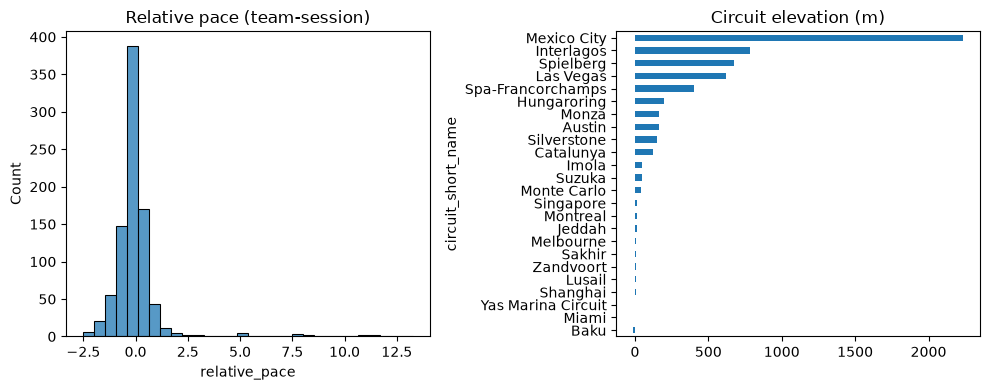

In [60]:
# relative pace + elevation distributions
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df["relative_pace"], bins=30, ax=axes[0])
axes[0].set_title("Relative pace (team-session)")
elev = df.groupby("circuit_short_name")["elevation_m"].first().sort_values()
elev.plot(kind="barh", ax=axes[1])
axes[1].set_title("Circuit elevation (m)")
plt.tight_layout()
plt.show()


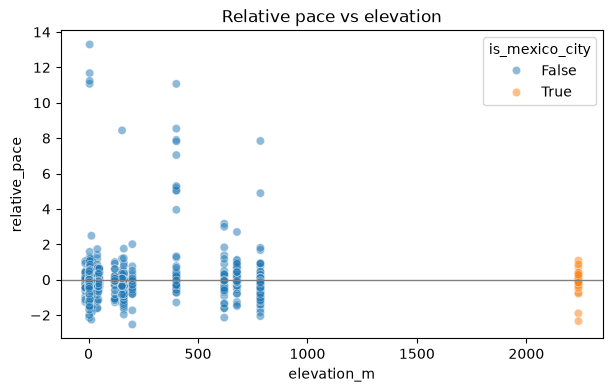

In [61]:
# elevation vs relative pace; hue = high-altitude track flag
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="elevation_m", y="relative_pace", hue="is_mexico_city", alpha=0.5, legend=True)
plt.legend(title="high altitude")
plt.axhline(0, color="gray", lw=1)
plt.title("Relative pace vs elevation")
plt.show()


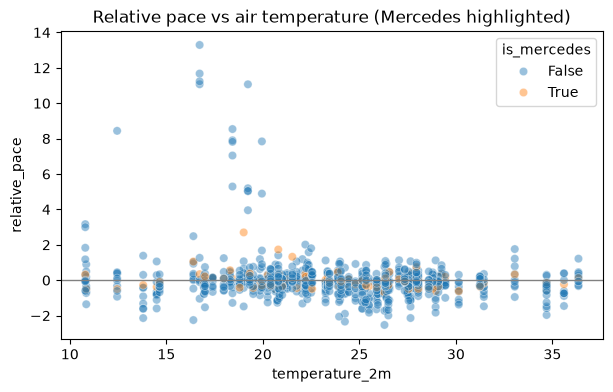

In [62]:
# Mercedes vs others: relative pace vs temperature
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="temperature_2m", y="relative_pace", hue="is_mercedes", alpha=0.45)
plt.axhline(0, color="gray", lw=1)
plt.title("Relative pace vs air temperature (Mercedes highlighted)")
plt.show()


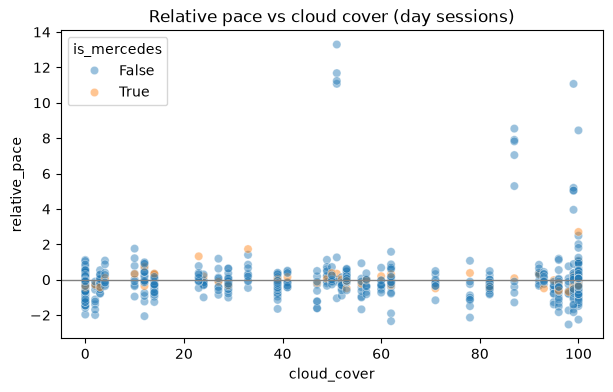

In [63]:
# Cloud cover (daytime sessions only)
day = df[~df["is_night"]]
plt.figure(figsize=(7, 4))
sns.scatterplot(data=day, x="cloud_cover", y="relative_pace", hue="is_mercedes", alpha=0.45)
plt.axhline(0, color="gray", lw=1)
plt.title("Relative pace vs cloud cover (day sessions)")
plt.show()


In [64]:
# Quick correlations among numeric predictors / outcome
df[["relative_pace", "temperature_2m", "cloud_cover", "elevation_m"]].corr().round(3)


,relative_pace,temperature_2m,cloud_cover,elevation_m
relative_pace,1.000,-0.183,0.081,0.017
temperature_2m,-0.183,1.000,-0.142,-0.074
cloud_cover,0.081,-0.142,1.000,0.054
elevation_m,0.017,-0.074,0.054,1.000


**Coverage / basic distributions**

Just checking we have similar amounts of data across years and teams, and that temperature / cloud cover / night races actually vary.

In [ ]:
# how much data we have by year / team
print("Rows by year:")
display(df["year"].value_counts().sort_index().to_frame("n_team_sessions"))

print("Rows by team:")
display(df["team_name"].value_counts().sort_values(ascending=False).to_frame("n_team_sessions"))

print("Team x year:")
display(pd.crosstab(df["team_name"], df["year"]))

In [ ]:
# temp, cloud cover, day vs night
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
sns.histplot(df["temperature_2m"], bins=20, ax=axes[0])
axes[0].set_title("Air temperature (°C)")
sns.histplot(df["cloud_cover"], bins=20, ax=axes[1])
axes[1].set_title("Cloud cover (%)")
sns.countplot(data=df.drop_duplicates("date_start_est"), x="is_night", ax=axes[2])
axes[2].set_title("Sessions: day vs night")
axes[2].set_xlabel("is_night")
plt.tight_layout()
plt.show()

print("Team-session rows — day:", (~df["is_night"]).sum(), "| night:", df["is_night"].sum())

**Elevation stuff (for Statement 1)**

Average relative pace at higher vs lower tracks by team, plus a quick check that the elevation pattern isn’t only coming from the highest tracks.

In [ ]:
# treat >1000m as "high" for a simple split
df = df.copy()
df["high_altitude"] = df["elevation_m"] > 1000

alt_team = (
    df.groupby(["team_name", "high_altitude"])["relative_pace"]
    .mean()
    .unstack("high_altitude")
    .rename(columns={False: "low_alt_mean_rp", True: "high_alt_mean_rp"})
)
alt_team["high_minus_low"] = alt_team["high_alt_mean_rp"] - alt_team["low_alt_mean_rp"]
display(alt_team.sort_values("high_minus_low"))

# scatter by team for a few teams we care about
focus = ["Ferrari", "Mercedes", "Red Bull Racing", "McLaren", "Alpine"]
focus = [t for t in focus if t in set(df["team_name"])]
g = sns.relplot(
    data=df[df["team_name"].isin(focus)],
    x="elevation_m",
    y="relative_pace",
    col="team_name",
    col_wrap=3,
    kind="scatter",
    alpha=0.55,
    height=3,
    aspect=1.1,
)
g.set_axis_labels("Elevation (m)", "Relative pace")
g.fig.suptitle("Relative pace vs elevation by team", y=1.02)
plt.show()

In [ ]:
# does the elevation correlation change if we drop high tracks?
full_corr = df["elevation_m"].corr(df["relative_pace"])
no_high = df.loc[~df["high_altitude"], ["elevation_m", "relative_pace"]].corr().iloc[0, 1]
print(f"corr(elevation, relative_pace) all: {full_corr:.3f}")
print(f"corr(elevation, relative_pace) no high-alt: {no_high:.3f}")
print("high-alt circuits:", sorted(df.loc[df["high_altitude"], "circuit_short_name"].unique()))

**Temperature / cloud stuff (for Statement 2)**

Mercedes vs everyone else in cooler vs warmer sessions, and same idea for cloud cover during the day. Just descriptive — not the actual regressions yet.

In [ ]:
# split temperature into 3 bands, compare Mercedes vs others
df["temp_band"] = pd.qcut(df["temperature_2m"], 3, labels=["cool", "mid", "warm"])
temp_cmp = (
    df.groupby(["is_mercedes", "temp_band"], observed=True)["relative_pace"]
    .agg(mean="mean", median="median", n="count")
)
display(temp_cmp)

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="temp_band", y="relative_pace", hue="is_mercedes")
plt.title("Relative pace by temperature band (Mercedes vs others)")
plt.xlabel("Air temperature tercile")
plt.tight_layout()
plt.show()

# same idea for cloud cover, daytime only
day = df.loc[~df["is_night"]].copy()
day["cloud_band"] = pd.qcut(day["cloud_cover"], 3, labels=["clear", "mixed", "cloudy"])
cloud_cmp = (
    day.groupby(["is_mercedes", "cloud_band"], observed=True)["relative_pace"]
    .agg(mean="mean", median="median", n="count")
)
display(cloud_cmp)

plt.figure(figsize=(7, 4))
sns.boxplot(data=day, x="cloud_band", y="relative_pace", hue="is_mercedes")
plt.title("Relative pace by daytime cloud band (Mercedes vs others)")
plt.xlabel("Cloud cover tercile (day sessions)")
plt.tight_layout()
plt.show()

In [ ]:
# overall Mercedes vs others (means should be near 0 since relative_pace is within-team)
plt.figure(figsize=(5, 4))
sns.boxplot(data=df, x="is_mercedes", y="relative_pace")
plt.title("Relative pace: Mercedes vs other teams")
plt.xlabel("is_mercedes")
plt.tight_layout()
plt.show()

display(df.groupby("is_mercedes")["relative_pace"].agg(["mean", "median", "std", "count"]))

**What we learned from EDA**

- Years look pretty even (~280–300 team-sessions each). Some teams show up under different names across seasons (rebrands), which we’ll need to be careful with for the team dummies.
- `relative_pace` is around 0 on average (by construction). There’s a long right tail from a few really slow weekends.
- Temperature and cloud cover jump around a lot. Most sessions are during the day, so limiting the cloud plot/analysis to daytime makes sense.
- High vs low altitude means differ by team. The elevation correlation also changes a bit if we drop the highest tracks, so the robustness check in Statement 1 seems worth doing.
- The cool/warm and clear/cloudy boxplots don’t scream “Mercedes advantage” on their own. That’s fine — the interaction models are what we’ll use later.
- Still planning to stick with the same research questions above.
